# Optimization Results — TSP + MDS (comparación cruzada)

**Este notebook NO entrena / NO resuelve.**

Lee las métricas ya generadas en:
- `Notebooks/Optimization/TSPOptimization/metrics/*_tsp.json`
- `Notebooks/Optimization/MinimumDominatingSetOptimization/metrics/*_mds.json`

Para cada solver (brute force, greedy, ILP, QUBO+SA, QAOA, VQE) compara **TSP** y **MDS**
y promedia solo métricas comparables entre problemas:
- `success_rate`
- `gap_rel = gap_mean / optimal_cost` (el coste absoluto no es comparable: ~16 vs ~2)
- `time_mean_s`

> No es un meta-análisis estadístico; es un resumen de defensa / documento.
> Fuerza bruta “gana” en tiempo aquí porque ambas instancias son pequeñas; no escala.


## Cargar métricas TSP y MDS


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def resolve_optimization_dir() -> Path:
    for base in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        root = base / "Notebooks" / "Optimization"
        if root.is_dir():
            return root
    return Path.cwd().resolve() / "Notebooks" / "Optimization"


OPT_DIR = resolve_optimization_dir()
TSP_METRICS = OPT_DIR / "TSPOptimization" / "metrics"
MDS_METRICS = OPT_DIR / "MinimumDominatingSetOptimization" / "metrics"
OUT_DIR = OPT_DIR / "OveralOptimization"
FIGURES_DIR = OUT_DIR / "figures"
METRICS_DIR = OUT_DIR / "metrics"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

EXPECTED = {
    "brute_force": ("bruteforce_tsp.json", "bruteforce_mds.json"),
    "greedy": ("greedy_tsp.json", "greedy_mds.json"),
    "ilp": ("ilp_tsp.json", "ilp_mds.json"),
    "simulated_annealing": ("sa_tsp.json", "sa_mds.json"),
    "qaoa": ("qaoa_tsp.json", "qaoa_mds.json"),
    "vqe": ("vqe_tsp.json", "vqe_mds.json"),
}
ALL_SOLVERS = list(EXPECTED.keys())
PROBLEMS = ["tsp", "mds"]


def load_json(path: Path) -> dict:
    if not path.exists():
        raise FileNotFoundError(path)
    return json.loads(path.read_text())


def row_from_payload(problem: str, solver: str, payload: dict) -> dict:
    q = payload["quality"]
    opt = float(q.get("optimal_cost") or 0.0)
    gap = float(q.get("gap_mean") if q.get("gap_mean") is not None else np.nan)
    gap_rel = float(gap / opt) if opt and not np.isnan(gap) else np.nan
    return {
        "problem": problem,
        "solver": solver,
        "family": payload.get("family", "classical"),
        "success_rate": float(payload["success_rate"]),
        "cost_mean": q.get("cost_mean"),
        "cost_best": q.get("cost_best"),
        "gap_mean": gap,
        "gap_rel": gap_rel,
        "optimal_cost": opt,
        "time_mean_s": float(payload["time_s"]["mean"]),
        "time_std_s": payload["time_s"].get("std"),
        "energy_evals_mean": payload.get("effort", {}).get("energy_evals_mean"),
    }


tsp_raw, mds_raw = {}, {}
missing = []
for solver, (tsp_file, mds_file) in EXPECTED.items():
    tp, mp = TSP_METRICS / tsp_file, MDS_METRICS / mds_file
    if not tp.exists():
        missing.append(str(tp))
    else:
        tsp_raw[solver] = load_json(tp)
    if not mp.exists():
        missing.append(str(mp))
    else:
        mds_raw[solver] = load_json(mp)

if missing:
    raise FileNotFoundError(
        "Faltan métricas. Ejecuta antes los notebooks TSP y MDS.\n"
        + "\n".join(f" - {m}" for m in missing)
    )

per_rows = []
for solver in ALL_SOLVERS:
    per_rows.append(row_from_payload("tsp", solver, tsp_raw[solver]))
    per_rows.append(row_from_payload("mds", solver, mds_raw[solver]))

df_per = pd.DataFrame(per_rows)
print(f"Loaded TSP+MDS for {len(ALL_SOLVERS)} solvers from\n  {TSP_METRICS}\n  {MDS_METRICS}")
print(df_per[["problem", "solver", "success_rate", "gap_rel", "time_mean_s"]].round(4).to_string(index=False))


Loaded TSP+MDS for 6 solvers from
  /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/TSPOptimization/metrics
  /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/MinimumDominatingSetOptimization/metrics
problem              solver  success_rate  gap_rel  time_mean_s
    tsp         brute_force         1.000   0.0000       0.0009
    mds         brute_force         1.000   0.0000       0.0002
    tsp              greedy         1.000   0.0000       0.0005
    mds              greedy         0.000   0.5000       0.0000
    tsp                 ilp         1.000   0.0000       1.2768
    mds                 ilp         1.000   0.0000       0.6658
    tsp simulated_annealing         0.900   0.0188       0.0172
    mds simulated_annealing         1.000   0.0000       0.0079
    tsp                qaoa         1.000   0.0000       1.0588
    mds                qaoa         0.875   0.1250      12.2316
    t

## Tabla consolidada (media TSP + MDS)


In [2]:
mean_rows = []
for solver in ALL_SOLVERS:
    sub = df_per[df_per["solver"] == solver]
    mean_rows.append({
        "solver": solver,
        "family": sub["family"].iloc[0],
        "problems": ["tsp", "mds"],
        "success_rate": float(sub["success_rate"].mean()),
        "gap_rel": float(sub["gap_rel"].mean()),
        "time_mean_s": float(sub["time_mean_s"].mean()),
        "success_tsp": float(sub.loc[sub["problem"] == "tsp", "success_rate"].iloc[0]),
        "success_mds": float(sub.loc[sub["problem"] == "mds", "success_rate"].iloc[0]),
        "gap_rel_tsp": float(sub.loc[sub["problem"] == "tsp", "gap_rel"].iloc[0]),
        "gap_rel_mds": float(sub.loc[sub["problem"] == "mds", "gap_rel"].iloc[0]),
        "time_tsp": float(sub.loc[sub["problem"] == "tsp", "time_mean_s"].iloc[0]),
        "time_mds": float(sub.loc[sub["problem"] == "mds", "time_mean_s"].iloc[0]),
    })

df = pd.DataFrame(mean_rows)
print(df.round(4).to_string(index=False))


             solver           family   problems  success_rate  gap_rel  time_mean_s  success_tsp  success_mds  gap_rel_tsp  gap_rel_mds  time_tsp  time_mds
        brute_force        classical [tsp, mds]        1.0000   0.0000       0.0005          1.0        1.000       0.0000        0.000    0.0009    0.0002
             greedy        classical [tsp, mds]        0.5000   0.2500       0.0003          1.0        0.000       0.0000        0.500    0.0005    0.0000
                ilp        classical [tsp, mds]        1.0000   0.0000       0.9713          1.0        1.000       0.0000        0.000    1.2768    0.6658
simulated_annealing        classical [tsp, mds]        0.9500   0.0094       0.0125          0.9        1.000       0.0188        0.000    0.0172    0.0079
               qaoa quantum_inspired [tsp, mds]        0.9375   0.0625       6.6452          1.0        0.875       0.0000        0.125    1.0588   12.2316
                vqe quantum_inspired [tsp, mds]        1.0000   

## Estilo y paleta


In [3]:
CLASSICAL_SOLVERS = ["brute_force", "greedy", "ilp", "simulated_annealing"]
QUANTUM_SOLVERS = ["qaoa", "vqe"]

SOLVER_COLORS = {
    "brute_force": "#0B1F33",
    "greedy": "#0E4A75",
    "ilp": "#4A5560",
    "simulated_annealing": "#219BC3",
    "qaoa": "#7EC8E3",
    "vqe": "#A8D5E5",
}
FAMILY_COLORS = {"classical": "#0E4A75", "quantum_inspired": "#A8D5E5"}
PROBLEM_COLORS = {"tsp": "#0E4A75", "mds": "#219BC3", "mean": "#4A5560"}

UNIR_NAVY = "#0E4A75"
UNIR_GRIS = "#858591"
UNIR_CLARO = "#C0C0C8"

plt.rcParams.update({
    "font.sans-serif": ["Arial", "DejaVu Sans", "Helvetica"],
    "axes.edgecolor": UNIR_CLARO,
    "grid.color": UNIR_CLARO,
    "grid.linestyle": "--",
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "figure.dpi": 150,
    "legend.fontsize": 9,
})

DISPLAY_NAME = {
    "brute_force": "Brute force",
    "greedy": "Greedy",
    "ilp": "ILP",
    "simulated_annealing": "QUBO + SA",
    "qaoa": "QAOA",
    "vqe": "VQE",
}
PROBLEM_LABEL = {"tsp": "TSP", "mds": "MDS", "mean": "Media"}

df["display"] = [DISPLAY_NAME[s] for s in df["solver"]]
df_per["display"] = [DISPLAY_NAME[s] for s in df_per["solver"]]


def savefig(name):
    path = FIGURES_DIR / name
    plt.savefig(path, bbox_inches="tight", facecolor="white")
    print("Saved:", path)
    plt.show()


def annotate_bars(ax, container, fmt="{:.2f}", dy=None, fontsize=8):
    for bar in container:
        h = bar.get_height()
        if np.isnan(h):
            continue
        offset = (0.02 * max(ax.get_ylim()[1], 1e-9)) if dy is None else dy
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            h + offset,
            fmt.format(h),
            ha="center",
            va="bottom",
            fontsize=fontsize,
            color=UNIR_GRIS,
        )


summary_path = METRICS_DIR / "optimization_mean_summary.csv"
df.to_csv(summary_path, index=False)
per_path = METRICS_DIR / "optimization_per_problem.csv"
df_per.to_csv(per_path, index=False)
print("Saved:", summary_path)
print("Saved:", per_path)


Saved: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/OveralOptimization/metrics/optimization_mean_summary.csv
Saved: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/OveralOptimization/metrics/optimization_per_problem.csv


### 0. TSP vs MDS vs media — Success rate (slide clave)


Saved: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/OveralOptimization/figures/opt_tsp_vs_mds_vs_mean_success.png


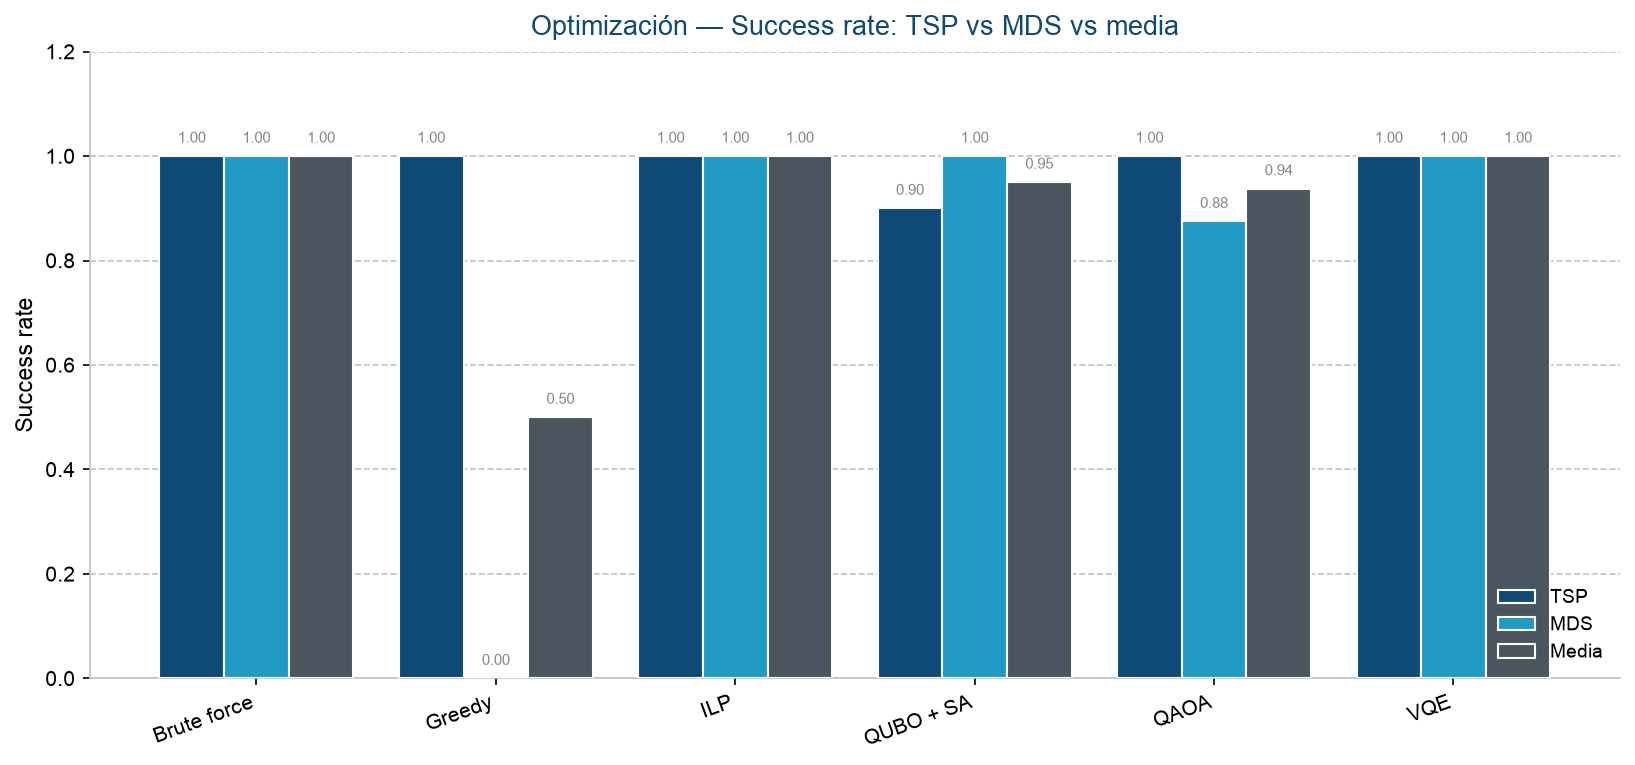

In [4]:
fig, ax = plt.subplots(figsize=(11, 5.2))
x = np.arange(len(ALL_SOLVERS))
w = 0.27
b1 = ax.bar(x - w, df["success_tsp"], width=w, color=PROBLEM_COLORS["tsp"],
            edgecolor="white", label="TSP", zorder=3)
b2 = ax.bar(x, df["success_mds"], width=w, color=PROBLEM_COLORS["mds"],
            edgecolor="white", label="MDS", zorder=3)
b3 = ax.bar(x + w, df["success_rate"], width=w, color=PROBLEM_COLORS["mean"],
            edgecolor="white", label="Media", zorder=3)
annotate_bars(ax, b1, fmt="{:.2f}", dy=0.02, fontsize=7)
annotate_bars(ax, b2, fmt="{:.2f}", dy=0.02, fontsize=7)
annotate_bars(ax, b3, fmt="{:.2f}", dy=0.02, fontsize=7)
ax.set_xticks(x)
ax.set_xticklabels([DISPLAY_NAME[s] for s in ALL_SOLVERS], rotation=20, ha="right")
ax.set_ylim(0, 1.2)
ax.set_ylabel("Success rate")
ax.set_title("Optimización — Success rate: TSP vs MDS vs media", color=UNIR_NAVY, pad=8)
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
savefig("opt_tsp_vs_mds_vs_mean_success.png")


### 1. Success rate medio por solver


Saved: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/OveralOptimization/figures/opt_success_rate_mean.png


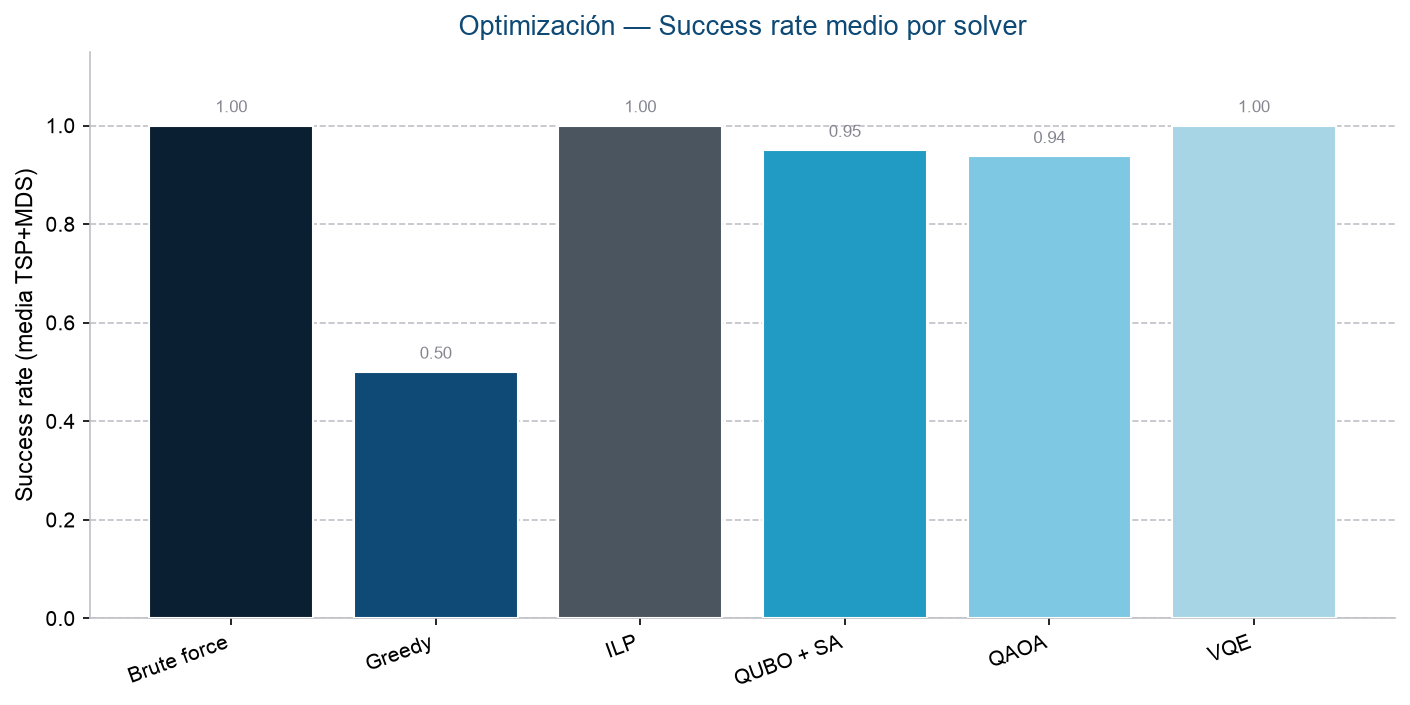

In [5]:
fig, ax = plt.subplots(figsize=(9.5, 4.8))
x = np.arange(len(ALL_SOLVERS))
colors = [SOLVER_COLORS[s] for s in ALL_SOLVERS]
bars = ax.bar(x, df["success_rate"], color=colors, edgecolor="white", zorder=3)
annotate_bars(ax, bars, fmt="{:.2f}", dy=0.02)
ax.set_xticks(x)
ax.set_xticklabels([DISPLAY_NAME[s] for s in ALL_SOLVERS], rotation=20, ha="right")
ax.set_ylim(0, 1.15)
ax.set_ylabel("Success rate (media TSP+MDS)")
ax.set_title("Optimización — Success rate medio por solver", color=UNIR_NAVY, pad=8)
ax.grid(axis="y", zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
savefig("opt_success_rate_mean.png")


### 2. Gap relativo: TSP vs MDS vs media

`gap_rel = (cost − optimal) / optimal` — comparable entre problemas.


Saved: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/OveralOptimization/figures/opt_tsp_vs_mds_vs_mean_gap_rel.png


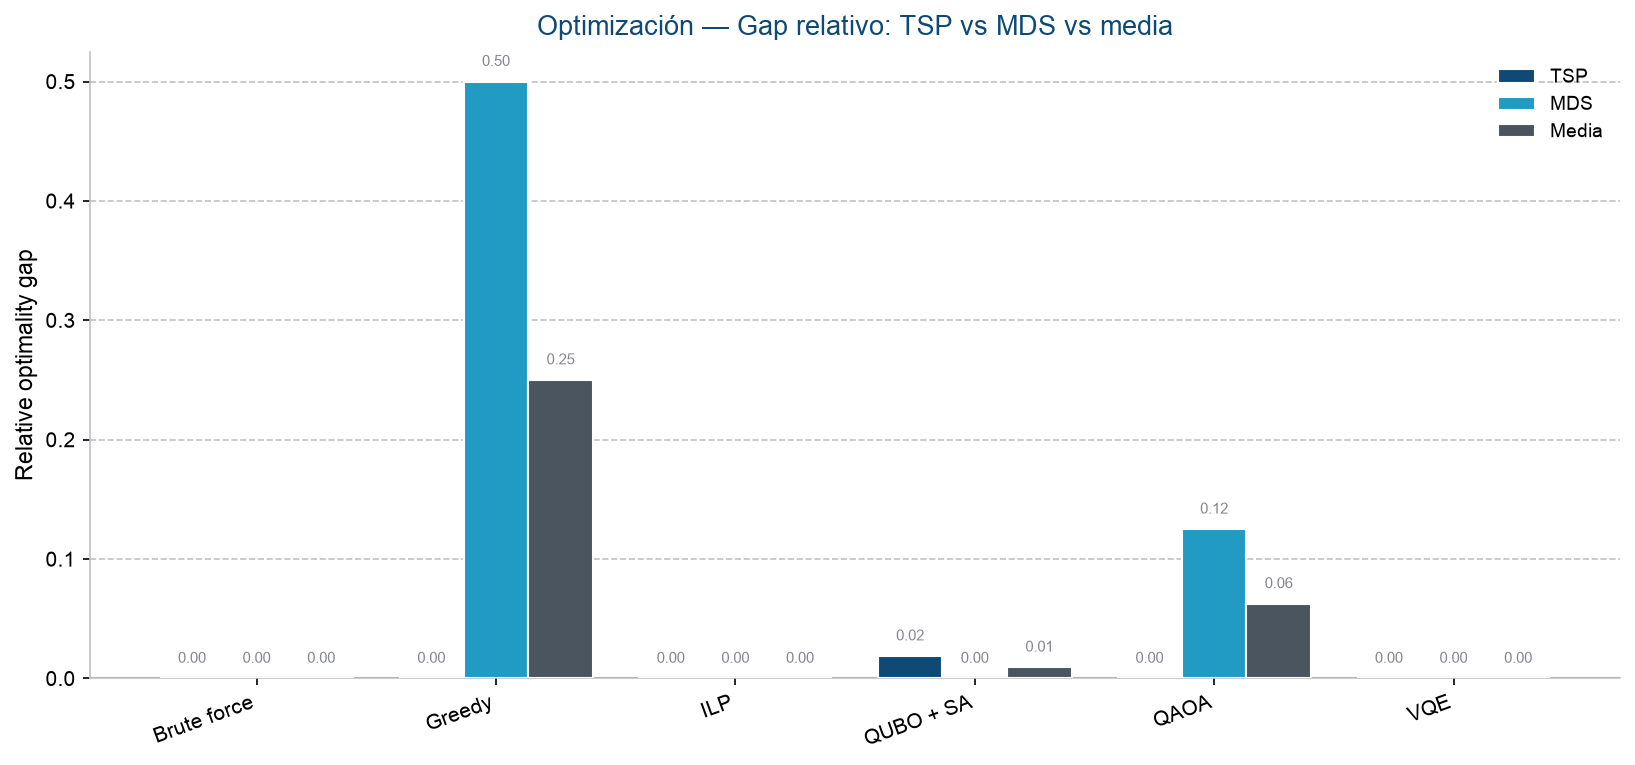

In [6]:
fig, ax = plt.subplots(figsize=(11, 5.2))
x = np.arange(len(ALL_SOLVERS))
w = 0.27
b1 = ax.bar(x - w, df["gap_rel_tsp"], width=w, color=PROBLEM_COLORS["tsp"],
            edgecolor="white", label="TSP", zorder=3)
b2 = ax.bar(x, df["gap_rel_mds"], width=w, color=PROBLEM_COLORS["mds"],
            edgecolor="white", label="MDS", zorder=3)
b3 = ax.bar(x + w, df["gap_rel"], width=w, color=PROBLEM_COLORS["mean"],
            edgecolor="white", label="Media", zorder=3)
annotate_bars(ax, b1, fmt="{:.2f}", fontsize=7)
annotate_bars(ax, b2, fmt="{:.2f}", fontsize=7)
annotate_bars(ax, b3, fmt="{:.2f}", fontsize=7)
ax.axhline(0, color=UNIR_GRIS, lw=1)
ax.set_xticks(x)
ax.set_xticklabels([DISPLAY_NAME[s] for s in ALL_SOLVERS], rotation=20, ha="right")
ax.set_ylabel("Relative optimality gap")
ax.set_title("Optimización — Gap relativo: TSP vs MDS vs media", color=UNIR_NAVY, pad=8)
ax.legend(frameon=False)
ax.grid(axis="y", zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
savefig("opt_tsp_vs_mds_vs_mean_gap_rel.png")


### 3. Clásicos vs quantum-inspired (media)


Saved: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/OveralOptimization/figures/opt_classical_vs_quantum_mean.png


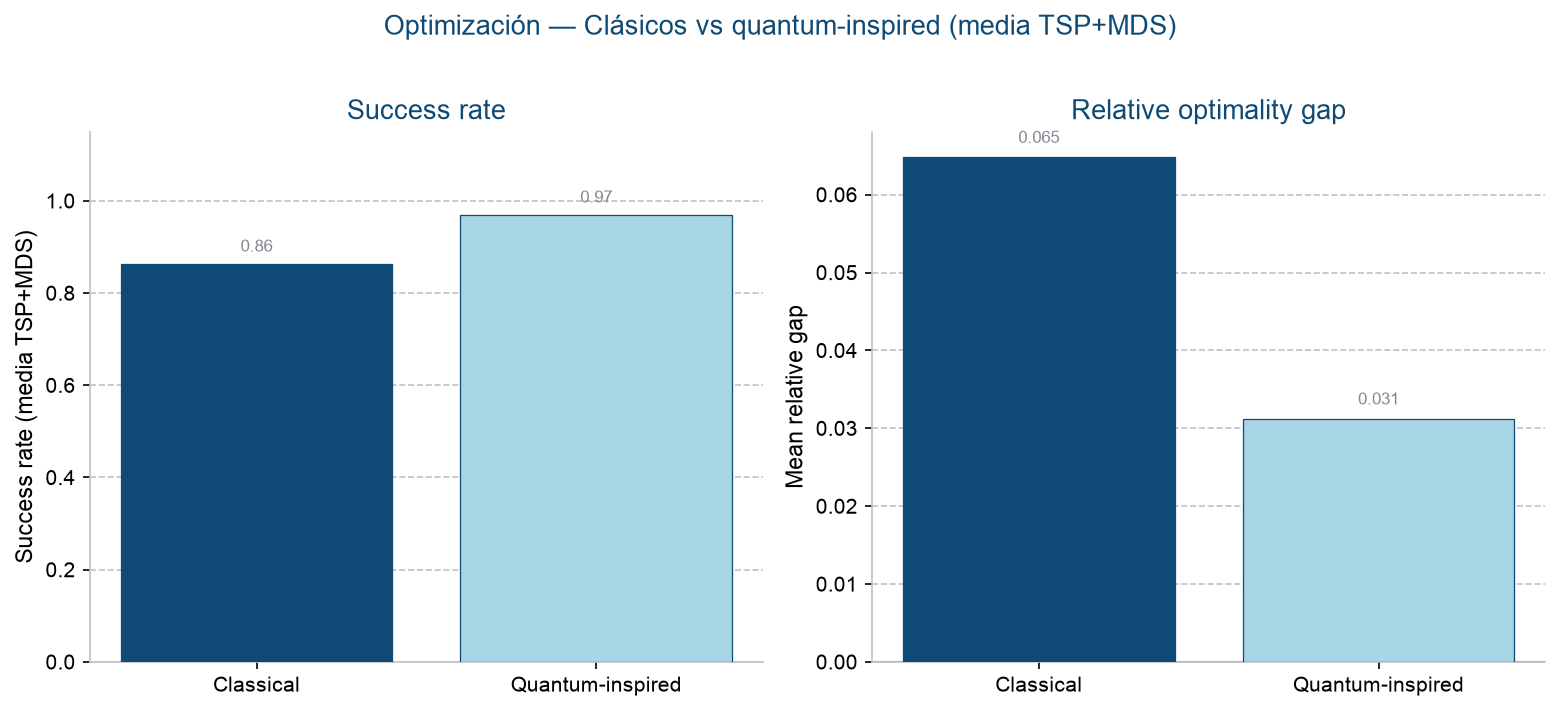

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(10.5, 4.6))
classic = df[df["family"] == "classical"]
quantum = df[df["family"] == "quantum_inspired"]

vals_s = [classic["success_rate"].mean(), quantum["success_rate"].mean()]
b1 = axs[0].bar(
    ["Classical", "Quantum-inspired"],
    vals_s,
    color=[FAMILY_COLORS["classical"], FAMILY_COLORS["quantum_inspired"]],
    edgecolor="#0E4A75",
    linewidth=0.6,
    zorder=3,
)
annotate_bars(axs[0], b1, fmt="{:.2f}", dy=0.02)
axs[0].set_ylim(0, 1.15)
axs[0].set_ylabel("Success rate (media TSP+MDS)")
axs[0].set_title("Success rate", color=UNIR_NAVY)
axs[0].grid(axis="y", zorder=0)
axs[0].spines["top"].set_visible(False)
axs[0].spines["right"].set_visible(False)

vals_g = [classic["gap_rel"].mean(), quantum["gap_rel"].mean()]
b2 = axs[1].bar(
    ["Classical", "Quantum-inspired"],
    vals_g,
    color=[FAMILY_COLORS["classical"], FAMILY_COLORS["quantum_inspired"]],
    edgecolor="#0E4A75",
    linewidth=0.6,
    zorder=3,
)
annotate_bars(axs[1], b2, fmt="{:.3f}")
axs[1].axhline(0, color=UNIR_GRIS, lw=1)
axs[1].set_ylabel("Mean relative gap")
axs[1].set_title("Relative optimality gap", color=UNIR_NAVY)
axs[1].grid(axis="y", zorder=0)
axs[1].spines["top"].set_visible(False)
axs[1].spines["right"].set_visible(False)

fig.suptitle("Optimización — Clásicos vs quantum-inspired (media TSP+MDS)",
             color=UNIR_NAVY, y=1.02, fontsize=13)
fig.tight_layout()
savefig("opt_classical_vs_quantum_mean.png")


### 4. Success vs runtime (media; puntos por solver)


Saved: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/OveralOptimization/figures/opt_success_vs_runtime_mean.png


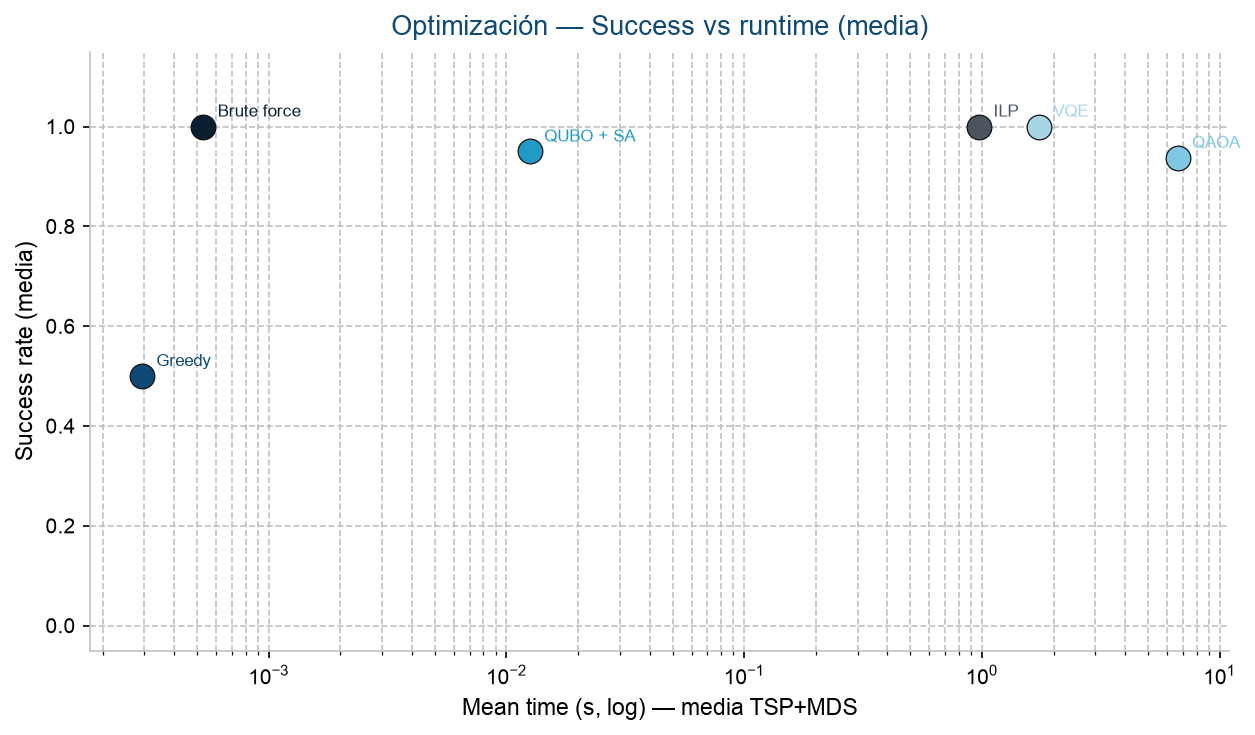

In [8]:
fig, ax = plt.subplots(figsize=(8.5, 5))
for _, row in df.iterrows():
    t = max(float(row["time_mean_s"]), 1e-6)
    ax.scatter(
        t,
        row["success_rate"],
        s=140,
        color=SOLVER_COLORS[row["solver"]],
        edgecolor="#111111",
        linewidth=0.6,
        zorder=3,
    )
    ax.text(
        t * 1.15,
        row["success_rate"] + 0.02,
        row["display"],
        fontsize=8,
        color=SOLVER_COLORS[row["solver"]],
    )
ax.set_xscale("log")
ax.set_xlabel("Mean time (s, log) — media TSP+MDS")
ax.set_ylabel("Success rate (media)")
ax.set_ylim(-0.05, 1.15)
ax.set_title("Optimización — Success vs runtime (media)", color=UNIR_NAVY, pad=8)
ax.grid(True, which="both", zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
savefig("opt_success_vs_runtime_mean.png")


### 5. Runtime: TSP vs MDS vs media (log)


Saved: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/OveralOptimization/figures/opt_runtime_tsp_vs_mds.png


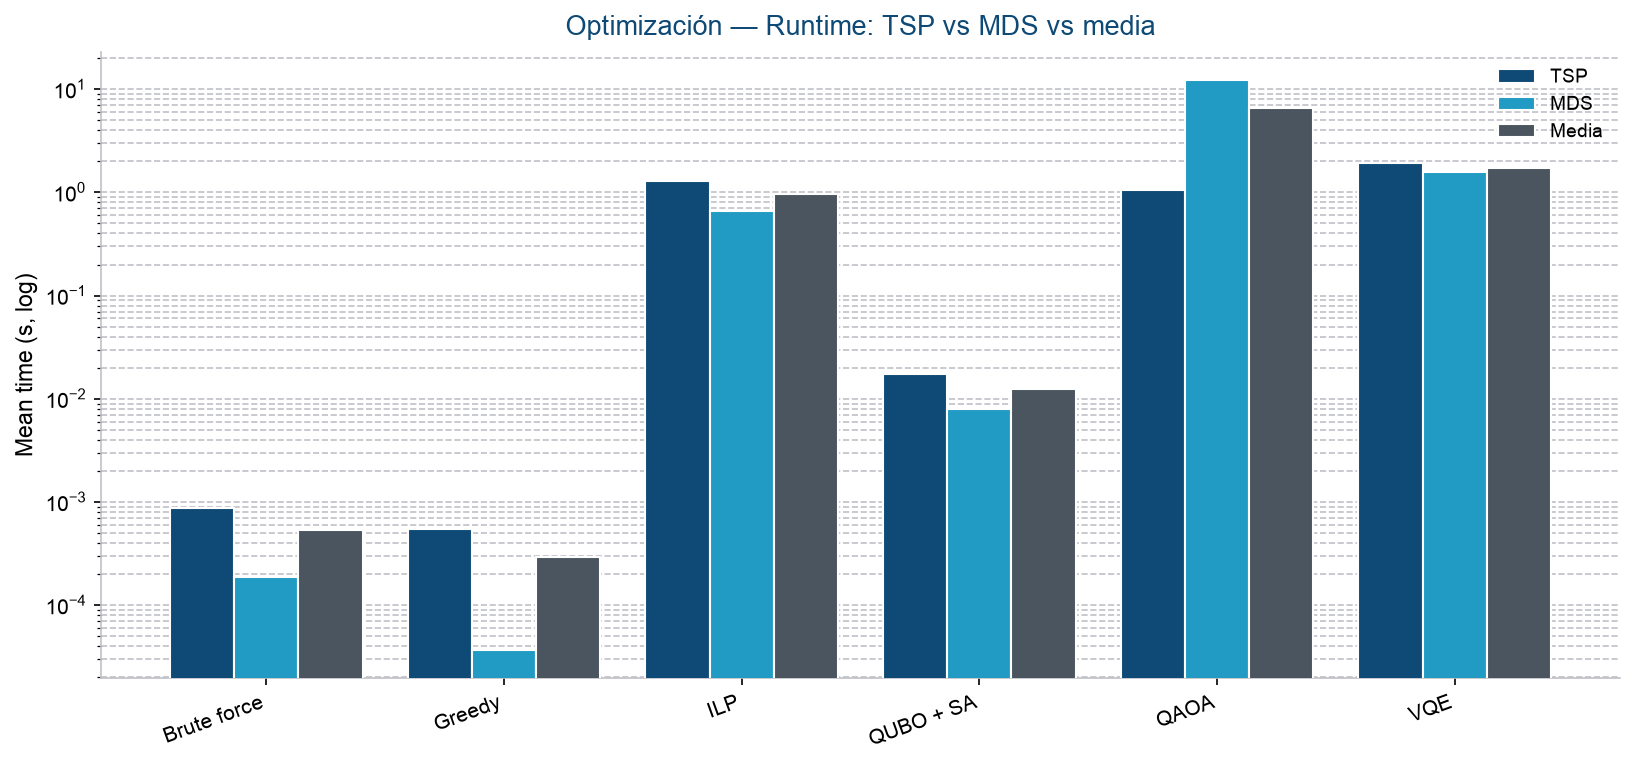

In [9]:
fig, ax = plt.subplots(figsize=(11, 5.2))
x = np.arange(len(ALL_SOLVERS))
w = 0.27
# use log via bar of log10 times for readability, but label real seconds
# Prefer grouped bars on log y-axis
vals_tsp = df["time_tsp"].clip(lower=1e-6)
vals_mds = df["time_mds"].clip(lower=1e-6)
vals_mean = df["time_mean_s"].clip(lower=1e-6)
b1 = ax.bar(x - w, vals_tsp, width=w, color=PROBLEM_COLORS["tsp"], edgecolor="white", label="TSP", zorder=3)
b2 = ax.bar(x, vals_mds, width=w, color=PROBLEM_COLORS["mds"], edgecolor="white", label="MDS", zorder=3)
b3 = ax.bar(x + w, vals_mean, width=w, color=PROBLEM_COLORS["mean"], edgecolor="white", label="Media", zorder=3)
ax.set_yscale("log")
ax.set_xticks(x)
ax.set_xticklabels([DISPLAY_NAME[s] for s in ALL_SOLVERS], rotation=20, ha="right")
ax.set_ylabel("Mean time (s, log)")
ax.set_title("Optimización — Runtime: TSP vs MDS vs media", color=UNIR_NAVY, pad=8)
ax.legend(frameon=False)
ax.grid(axis="y", which="both", zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
savefig("opt_runtime_tsp_vs_mds.png")


### 6. Heatmap resumen (métricas medias; más oscuro = mejor)


Saved: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/OveralOptimization/figures/opt_heatmap_mean.png


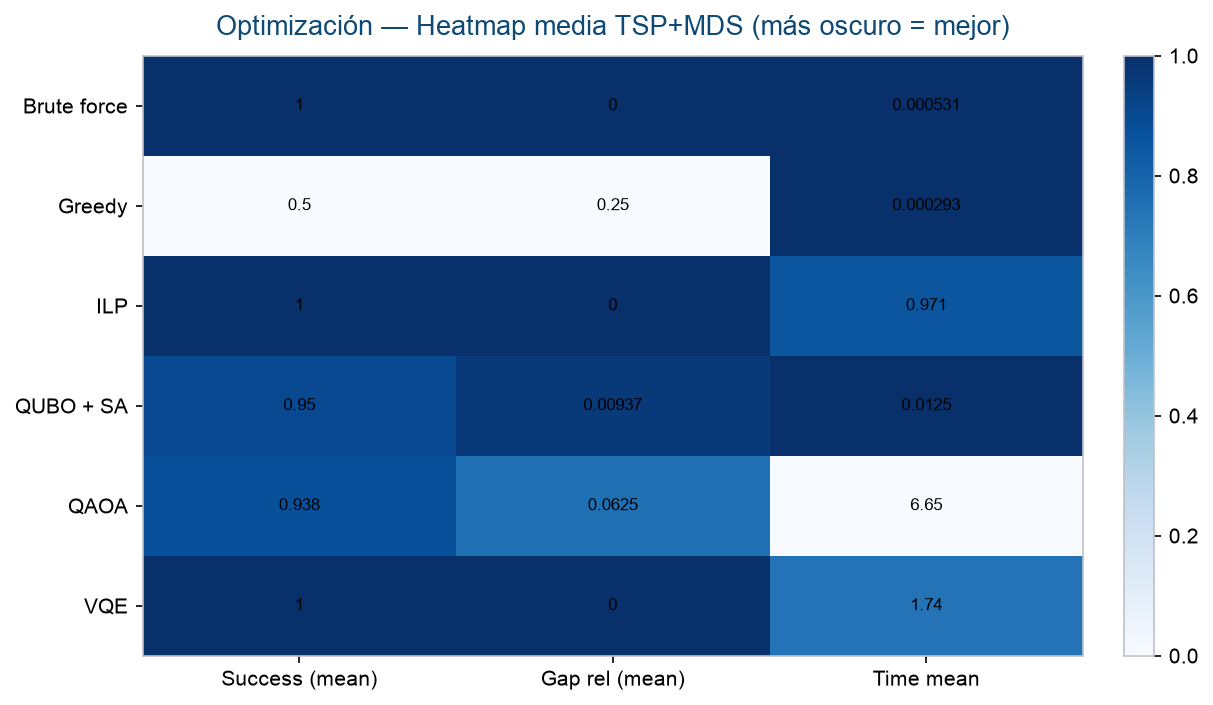

In [10]:
heat_cols = ["success_rate", "gap_rel", "time_mean_s"]
heat_labels = ["Success (mean)", "Gap rel (mean)", "Time mean"]
mat = df.set_index("solver").loc[ALL_SOLVERS, heat_cols]
norm = mat.copy()
for col in heat_cols:
    cmin, cmax = mat[col].min(), mat[col].max()
    if abs(cmax - cmin) < 1e-12:
        norm[col] = 0.5
    elif col in ("gap_rel", "time_mean_s"):
        norm[col] = 1 - (mat[col] - cmin) / (cmax - cmin)
    else:
        norm[col] = (mat[col] - cmin) / (cmax - cmin)

fig, ax = plt.subplots(figsize=(8.2, 4.8))
im = ax.imshow(norm.to_numpy(dtype=float), cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(heat_labels)))
ax.set_xticklabels(heat_labels)
ax.set_yticks(range(len(ALL_SOLVERS)))
ax.set_yticklabels([DISPLAY_NAME[s] for s in ALL_SOLVERS])
ax.set_title("Optimización — Heatmap media TSP+MDS (más oscuro = mejor)", color=UNIR_NAVY, pad=10)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        ax.text(j, i, f"{mat.iloc[i, j]:.3g}", ha="center", va="center", color="black", fontsize=8)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()
savefig("opt_heatmap_mean.png")


### 7. Takeaways (para documento / defensa)

1. **Comparar problemas con métricas relativas.** El coste absoluto de TSP (~16) y MDS (~2) no se promedia; sí `success_rate` y `gap_rel`.
2. **Brute force parece “mejor” en tiempo** porque ambas POCs son instancias pequeñas; no escala ($2^n$ / factorial).
3. **Quantum-inspired (QAOA/VQE)** iguala o se acerca al óptimo en calidad, con **mucho más runtime** que ILP/SA en estas tallas.
4. El valor del experimento es el **protocolo justo sobre el mismo QUBO**, no un veredicto de ventaja a esta escala.


## Archivos generados


In [11]:
print("Summary / detail tables:")
for p in sorted(METRICS_DIR.glob("*.csv")):
    print(" -", p)
print("\nFigures:")
for p in sorted(FIGURES_DIR.glob("opt_*.png")):
    print(" -", p)


Summary / detail tables:
 - /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/OveralOptimization/metrics/optimization_mean_summary.csv
 - /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/OveralOptimization/metrics/optimization_per_problem.csv

Figures:
 - /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/OveralOptimization/figures/opt_classical_vs_quantum_mean.png
 - /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/OveralOptimization/figures/opt_heatmap_mean.png
 - /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/OveralOptimization/figures/opt_runtime_tsp_vs_mds.png
 - /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/OveralOptimization/figures/opt_success_rate_mean.png
 - /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdv